### Random Forests and Photo-zs

En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [44]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14)
matplotlib.rc('ytick', labelsize=14)
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [45]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [46]:
#!pip install astropy
import astropy

from astropy.io import fits


#### Importamos los datos

Leemos el archivo fits y lo leemos usando pandas

In [47]:
with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
    arr = np.array(data[1].data)
    df = pd.DataFrame(arr.byteswap().view(arr.dtype.newbyteorder()))

In [48]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [49]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,b'',b'',b'11001673',b'1101',b'000',b'2003-05-06',52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"b'bext, bcol, possible OII'",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,b'GALAXY',b'',b'11001699',b'1100',b'7',b'2003-05-03',52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,b'',-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,b'GALAXY',b'',b'11001770',b'1101',b'003',b'2003-05-06',52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,b'',-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,b'GALAXY',b'',b'11001800',b'1100',b'004',b'2003-05-03',52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,b'',-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,b'GALAXY',b'',b'11001860',b'1101',b'10',b'2003-05-06',52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,b'',-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [50]:
df.shape

(23822, 78)

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [51]:
features = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor', 'y_apercor']]

In [52]:
target= df['zhelio']

### Ahora empezaremos a implementar nuestro modelo de Random Forest

Figura 5 del paper

 ![Performance of photometric redshift reconstruction](https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/mnras/488/4/10.1093_mnras_stz1866/1/stz1866fig5.jpeg?Expires=1764255560&Signature=YsogBmQvQ0CkbNXBEimFc23Rt9Slq~Q5qJGdV1YfvS3w-Z3IEJvD7FrYcOoSm6U0xY-gU~5JqYe2A7wjaHjQ~GAPOIZP8Kod-zh~1sxPBUDM3aj4kio313nsCcC-zCJRDd1OEvPncis9N7puYcPeqj2R3rSNaGk4QJCOBtGhE5-NLbwFbQFalDhy7dELFeMm4uZQxaCwNeJF1NsQBETobU-LK13KulZ51tMrLF1HiDEjQetQBvccYAG6sC2fTWrNNtv9lSl9PEaac9qHSycwfyDc8GeHPFyh~DmL7KSQM3V1PEEkjG6-RYrwZaXYBorj5PkR9ZLJQzoNqRxn4Gl7rg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA)

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [53]:
model = RandomForestRegressor()

In [54]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$

In [55]:


cv_esque = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(model, features, target, cv=cv_esque, return_train_score=True)

In [56]:
scores

{'fit_time': array([21.76166582, 21.7727077 , 21.97793794, 21.22221708, 21.91802621]),
 'score_time': array([0.18263221, 0.17900014, 0.23156095, 0.18359923, 0.19420958]),
 'test_score': array([0.34509619, 0.30243844, 0.29141402, 0.32279574, 0.30381563]),
 'train_score': array([0.87894886, 0.87541908, 0.87549943, 0.87559618, 0.8733742 ])}

Calcule el promedio y la desviación estándar de las métricas obtenidas.

In [57]:
print(f"R^2 Entrenamiento - Promedio: {scores['train_score'].mean():.4f} | Std: {scores['train_score'].std():.4f}")
print(f"R^2 Prueba - Promedio: {scores['test_score'].mean():.4f} | Std: {scores['test_score'].std():.4f}")

R^2 Entrenamiento - Promedio: 0.8758 | Std: 0.0018
R^2 Prueba - Promedio: 0.3131 | Std: 0.0189


**Qué puede decir de este resultado? Hay bias alto o varianza alta?**

Hay una alta varianza, por lo tanto un sobreajuste. Se observa que el modelo rinde muy bien con los datos entrenamiento R^2 = 0.8758, pero su desempeño cae fuertemente con los datos nuevos de prueba R^2 = 0.3131. El árbol practicamente estpa memorizando los datos en lugar de aprender a generalizar.

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [58]:
ypred = cross_val_predict(model, features, target, cv=cv_esque)

(0.0, 3.0)

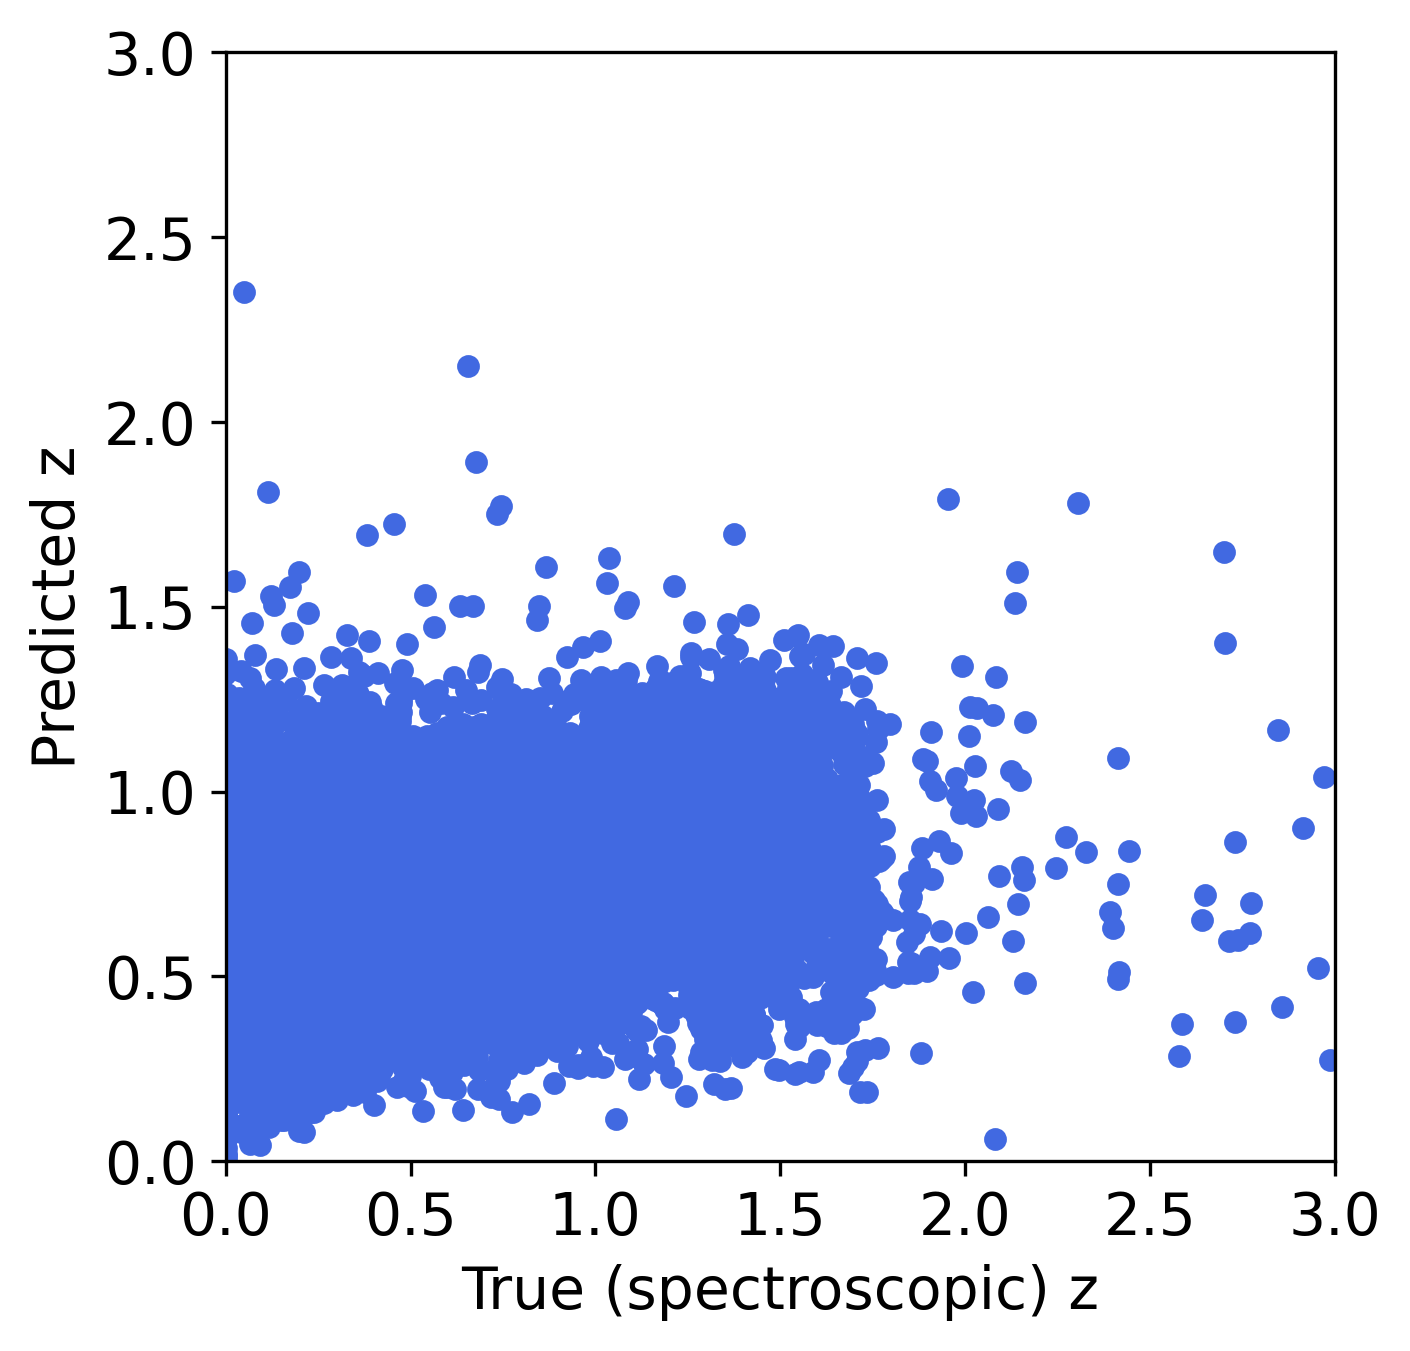

In [59]:
plt.scatter(target,ypred, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Se parece al resultado del paper??


No se parece en nada. La gráfica muestra una dispersión enorme que no sigue la diagonal esperada de la recta y=x. Esto ocurre porque el modelo fue entrenado con los datos crudos sin limpieza de datos sucios, por lo que es incapaz de capturar la relación física real para el redshift.

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha.

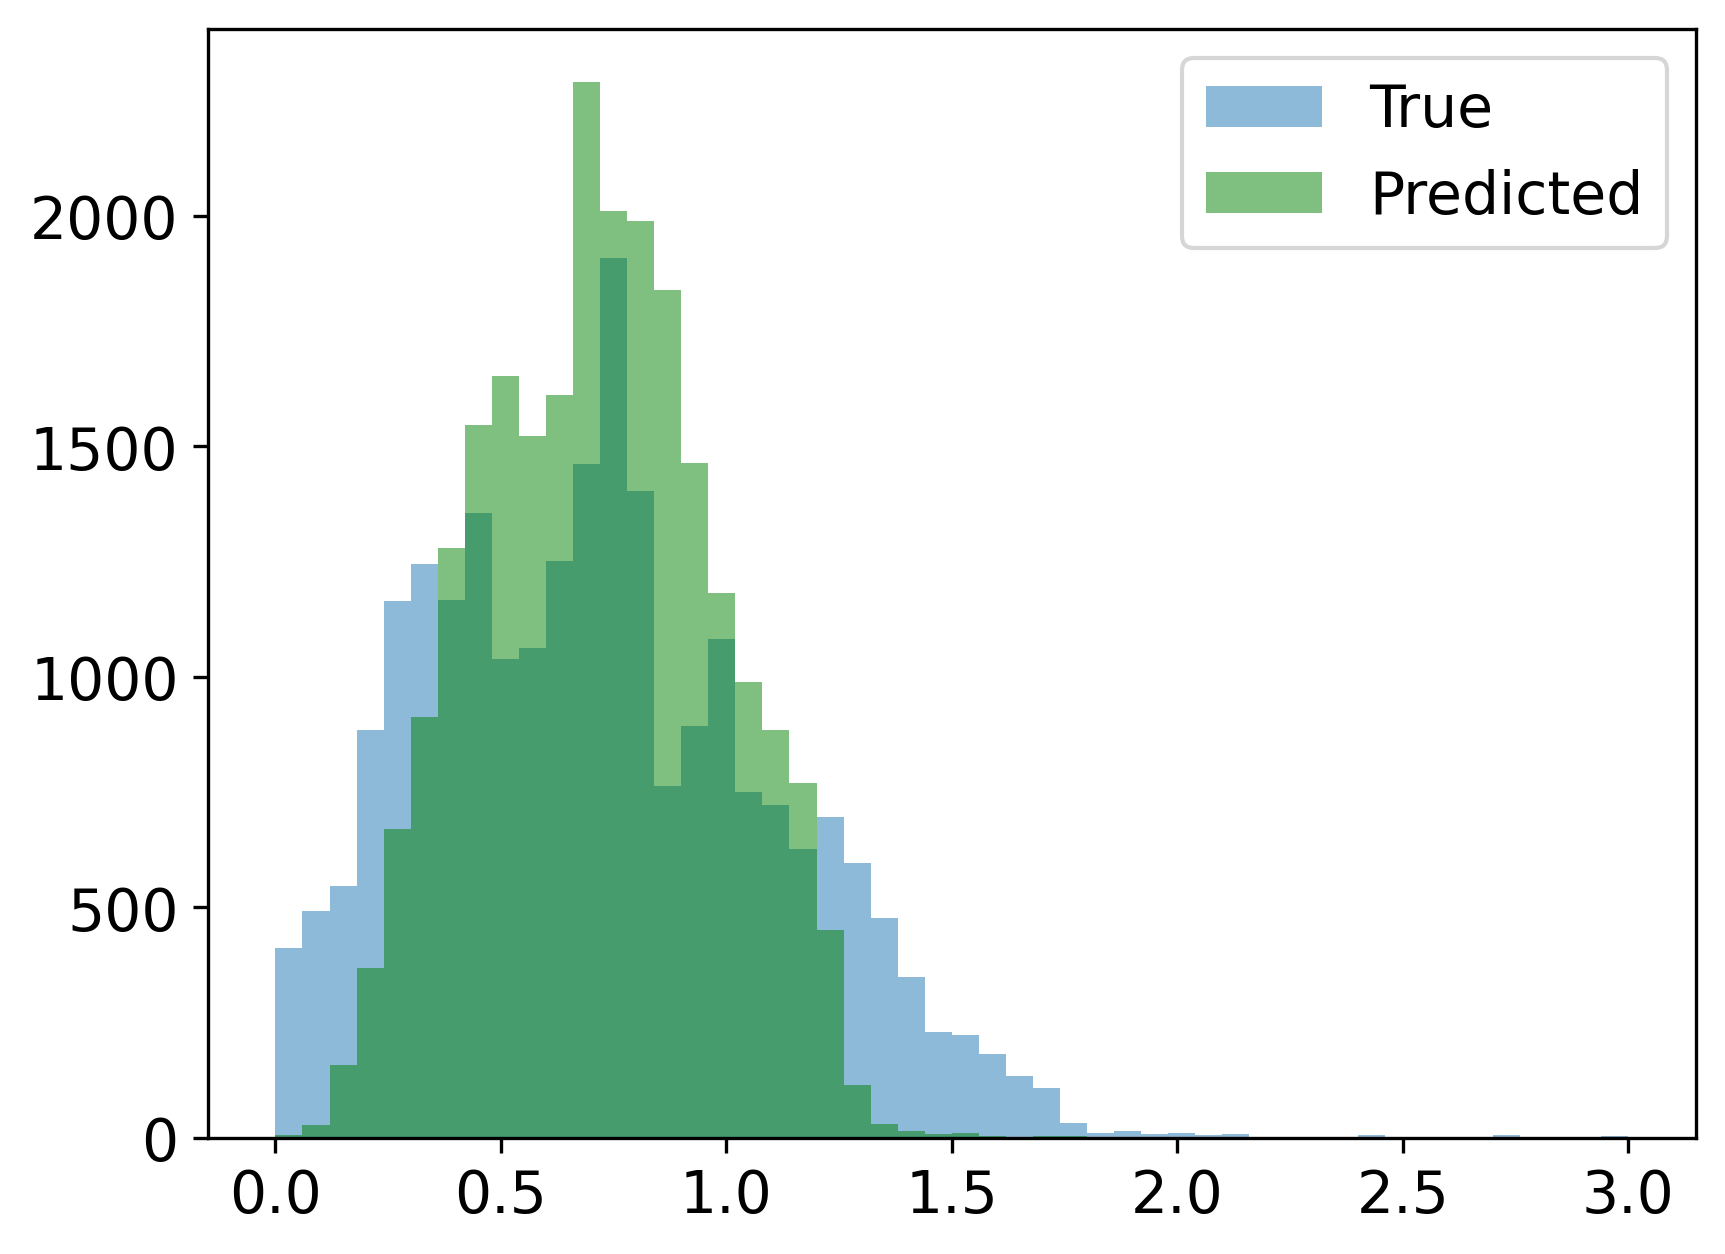

In [60]:
plt.hist(target,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);

Ahora calcule las métricas del paper, fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper

In [61]:

delta_z = ypred - target

# la condición del paper
outliers = np.abs(delta_z) > 0.15 * (1 + target)

# Calculamos eta
eta = np.sum(outliers) / len(target)
print(f"Fracción de outliers (eta): {eta:.4f}")

Fracción de outliers (eta): 0.2553


y NMAD

In [62]:

mad = np.median(np.abs(delta_z) / (1 + target))

sigma_nmad = 1.48 * mad
print(f"Sigma NMAD: {sigma_nmad:.4f}")

Sigma NMAD: 0.0751


Los valores que se obtuvieron (eta = 0.2553 y SigmaNMAD = 0.0751) son peores que los del paper donde eta ≈ 0.06 y SigmaNMAD = 0.0381. Esto evidencia que nuestro modelo base con datos crudos necesita ser optimizado y filtrado para alcanzar ese nivel de precisión.

### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [63]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), 5000, replace = False) #sample sin reemplazo

In [64]:
len(np.unique(sel))

5000

Y creamos nuestro nuevo dataset más pequeño

In [65]:
seld = features.loc[sel,:]
selt = target[sel]

Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [66]:
littlescores = cross_validate(model,seld,selt, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

In [67]:
littlescores['test_score'].mean(), littlescores['train_score'].mean()

(np.float64(0.27762715338769406), np.float64(0.8763722031531694))

### Estamos listos para optimizar hiperparámetros...cuáles escogemos?



#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [68]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper

- min_impurity_decrease

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [69]:
%%time
#Toma algunos minutos
parameters = {'min_impurity_decrease':[0.1, 0.5, 0.0], \
              'max_features':[None,4,2], 'n_estimators':[50, 100, 200], 'min_samples_split': [10,20,100],
              'max_leaf_nodes':[None, 100, 200]}



grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    parameters,
    cv=KFold(n_splits=5, shuffle=True, random_state=10),
    return_train_score=True,
    n_jobs=-1
)

grid_search.fit(seld, selt)


model = grid_search.best_estimator_

print(f"Best params: {grid_search.best_params_}")
print(f"Best score: {grid_search.best_score_:.4f}")

Best params: {'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 10, 'n_estimators': 200}
Best score: 0.3016
CPU times: user 9.9 s, sys: 913 ms, total: 10.8 s
Wall time: 15min 12s


Guardamos el resultado en un dataframe y buscamos el mejor modelo

In [70]:
scores = pd.DataFrame(grid_search.cv_results_)
scoresCV = scores[['params','mean_test_score','std_test_score','mean_train_score']].sort_values(by = 'mean_test_score', \
                                                    ascending = False)


In [71]:
scoresCV

,params,mean_test_score,std_test_score,mean_train_score
182,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.301607,0.034088,0.725586
180,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.298665,0.037634,0.719427
181,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.298626,0.037441,0.722874
104,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.297559,0.033307,0.651384
185,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.296324,0.030611,0.621141
...,...,...,...,...
216,"{'max_features': 2, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.1, 'min_samples_split': 10...",-0.000287,0.000163,-0.000006
225,"{'max_features': 2, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.5, 'min_samples_split': 10...",-0.000287,0.000163,-0.000006
222,"{'max_features': 2, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.1, 'min_samples_split': 10...",-0.000287,0.000163,-0.000006
231,"{'max_features': 2, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.5, 'min_samples_split': 10...",-0.000287,0.000163,-0.000006


### Mejoran los scores?

No hay una mejora real en el score de prueba.El mejor modelo optimizado alcanza un $R^2$ de prueba de 0.3016, que es casi idéntico al benchmark inicial. Lo que sí se logró fue reducir el sobreajuste (varianza), bajando el score de entrenamiento a 0.7255 (antes era ~0.87). Esto confirma que optimizar los hiperparámetros no compensa la falta de limpieza de los datos de entrada.

### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [72]:
mags = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor','subaru_source','cfhtls_source','zquality']]



In [73]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [74]:
mags.shape

(23822, 9)

In [75]:
#zquality - solo usa objetos con medición de redshift de buena calidad

mags = mags[mags['zquality'] >= 3]

mags.shape

(16857, 9)

In [76]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data

mags = mags[mags['cfhtls_source'] == 0]

mags.shape

(10671, 9)

Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [77]:
mags = mags[mags > -10].dropna()

In [78]:
mags.shape

(6371, 9)

In [79]:
mags = mags[mags < 90].dropna()

In [80]:
mags.shape

(6307, 9)

Tenemos un dataset con las 6 features originales y 6307 objetos

In [81]:
sel_features = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [82]:
sel_target = target[sel_features.index]

**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.**

In [83]:
scores_new = cross_validate(model, sel_features, sel_target, cv=cv_esque, return_train_score=True)

print(f"Nuevo R^2 Entrenamiento: {scores_new['train_score'].mean():.4f}")
print(f"Nuevo R^2 Prueba: {scores_new['test_score'].mean():.4f}")

Nuevo R^2 Entrenamiento: 0.9136
Nuevo R^2 Prueba: 0.7321


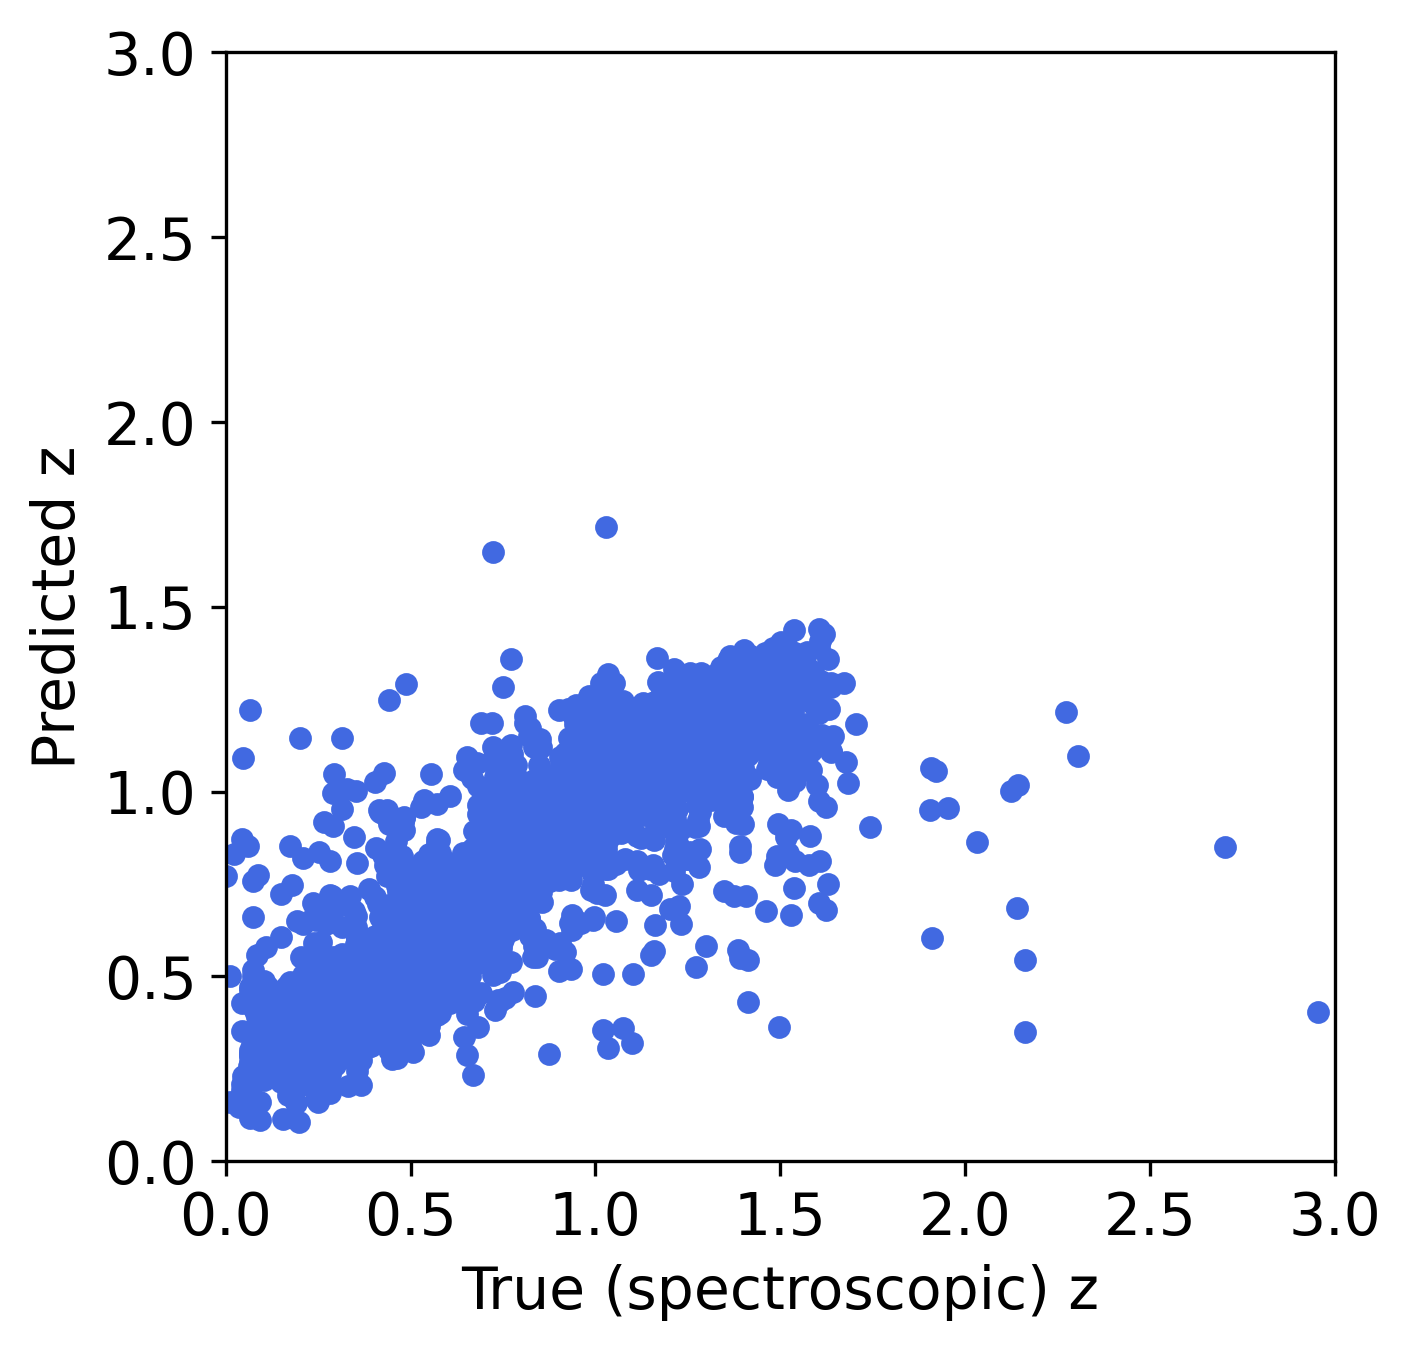

In [84]:
ypred_new = cross_val_predict(model, sel_features, sel_target, cv=cv_esque, n_jobs=-1)

plt.scatter(sel_target, ypred_new, s=20, c='royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z', fontsize=14)
plt.axis('square')
plt.xlim(0, 3)
plt.ylim(0, 3)
plt.show()

In [85]:
delta_z_new = ypred_new - sel_target

# Fracción de outliers (eta)
outliers_new = np.abs(delta_z_new) > 0.15 * (1 + sel_target)
eta_new = np.sum(outliers_new) / len(sel_target)
print(f"Nueva fracción de outliers (eta): {eta_new:.4f}")

# NMAD
mad_new = np.median(np.abs(delta_z_new) / (1 + sel_target))
sigma_nmad_new = 1.48 * mad_new
print(f"Nuevo Sigma NMAD: {sigma_nmad_new:.4f}")

Nueva fracción de outliers (eta): 0.0704
Nuevo Sigma NMAD: 0.0450


### Conclusion: Cómo se compara nuestro modelo con el resultado del paper?

Al limpiar los datos eliminando valores erróneos (-99) y de mala calidad, el $R^2$ de prueba mejora enormemente (de ~0.30 a 0.73) y el gráfico de dispersión se alinea mucho mejor a la diagonal, dando predicciones más correctas. Nuestras nuevas métricas ($\eta$ y $\sigma_{NMAD}$) ahora sí logran replicar los resultados mostrados en la Figura 5 del paper

Revise la sección 7 del paper. Podemos mejorar nuestro modelo
aún más? Implemente un nuevo modelo con la mejora identificada.

La Sección 7 del paper discute cómo la aleatoriedad ayuda a mitigar el alto sobreajuste (varianza) propio de los modelos basados en árboles. podemos llevar este concepto al nivel práctico usando la técnica de aleatorización Extra Random Trees. A diferencia de Random Forest, este algoritmo lleva la aleatorización un paso más allá al seleccionar aleatoriamente el valor umbral para la división (split) en cada nodo.   

Al implementar ExtraTreesRegressor, confirmamos esta mejora empíricamente. Nuestro modelo supera al Random Forest con el filtro de datos anterior, ya que el score $R^2$ de prueba aumenta de 0.7321 a 0.7663, la fracción de outliers ($\eta$) disminuye de 0.0704 a 0.0517, y la dispersión normalizada ($\sigma_{NMAD}$) se reduce de 0.0450 a 0.0328. Esto demuestra que una mayor aleatorización en los cortes ayuda al modelo a generalizar mejor, acercándonos aún más a la precisión reportada en el paper original.

In [86]:
# modelo ExtraTrees
extra_trees_model = ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# Evaluación con validacion cruzada
scores_et = cross_validate(extra_trees_model, sel_features, sel_target, cv=cv_esque, return_train_score=True)
print(f"Extra Trees - Test R^2: {scores_et['test_score'].mean():.4f}")

# generamos predicciones para calcular métricas
ypred_et = cross_val_predict(extra_trees_model, sel_features, sel_target, cv=cv_esque, n_jobs=-1)

delta_z_et = ypred_et - sel_target
eta_et = np.sum(np.abs(delta_z_et) > 0.15 * (1 + sel_target)) / len(sel_target)
sigma_nmad_et = 1.48 * np.median(np.abs(delta_z_et) / (1 + sel_target))

print(f"Extra Trees - Fracción de outliers (eta): {eta_et:.4f}")
print(f"Extra Trees - Sigma NMAD: {sigma_nmad_et:.4f}")

Extra Trees - Test R^2: 0.7663
Extra Trees - Fracción de outliers (eta): 0.0517
Extra Trees - Sigma NMAD: 0.0328
